In [1]:
# ==================================================
# IRIS FLOWER CLASSIFICATION
# CodeAlpha Data Science Internship
# Step 1: Import Required Libraries
# ==================================================

# Data Manipulation
import numpy as np
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
from sklearn.datasets import load_iris

# Data Splitting
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model Saving
import joblib
import os

# Display Settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# ==================================================
# Step 2: Load Iris Flower Dataset
# ==================================================

# Load the built-in Iris dataset
iris = load_iris()

# Display basic dataset information
print("=" * 50)
print("IRIS FLOWER DATASET INFORMATION")
print("=" * 50)

print("\nDataset loaded successfully!")

print("\nTotal Samples:", iris.data.shape[0])
print("Total Features:", iris.data.shape[1])

print("\nFeature Names:")
for feature in iris.feature_names:
    print("-", feature)

print("\nTarget Classes:")
for species in iris.target_names:
    print("-", species)

print("\nDataset loading completed successfully!")

IRIS FLOWER DATASET INFORMATION

Dataset loaded successfully!

Total Samples: 150
Total Features: 4

Feature Names:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Target Classes:
- setosa
- versicolor
- virginica

Dataset loading completed successfully!


In [3]:
# ==================================================
# Step 3: Create Pandas DataFrame
# ==================================================

# Define feature names
feature_names = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Create DataFrame
df = pd.DataFrame(iris.data, columns=feature_names)

# Add target column
df["target"] = iris.target

# Add flower species names
df["species"] = df["target"].map(
    dict(enumerate(iris.target_names))
)

# Display dataset information
print("DataFrame created successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

DataFrame created successfully!
Dataset Shape: (150, 6)

First 5 Records:


,sepal_length,sepal_width,petal_length,petal_width,target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [4]:
# ==================================================
# Step 4: Data Quality Analysis
# ==================================================

print("=" * 50)
print("IRIS DATASET - DATA QUALITY ANALYSIS")
print("=" * 50)

# Dataset shape
print("\n1. Dataset Shape:")
print(df.shape)

# Dataset information
print("\n2. Dataset Information:")
df.info()

# Missing values
print("\n3. Missing Values:")
print(df.isnull().sum())

# Duplicate records
print("\n4. Duplicate Rows:")
print(df.duplicated().sum())

# Statistical summary
print("\n5. Statistical Summary:")
display(df.describe().round(2))

print("\nData Quality Analysis Completed Successfully!")

IRIS DATASET - DATA QUALITY ANALYSIS

1. Dataset Shape:
(150, 6)

2. Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   target        150 non-null    int64  
 5   species       150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB

3. Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

4. Duplicate Rows:
1

5. Statistical Summary:


,sepal_length,sepal_width,petal_length,petal_width,target
count,150.00,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20,1.00
std,0.83,0.44,1.77,0.76,0.82
min,4.30,2.00,1.00,0.10,0.00
25%,5.10,2.80,1.60,0.30,0.00
50%,5.80,3.00,4.35,1.30,1.00
75%,6.40,3.30,5.10,1.80,2.00
max,7.90,4.40,6.90,2.50,2.00



Data Quality Analysis Completed Successfully!


In [5]:
# ==================================================
# Step 5: Data Cleaning
# ==================================================

print("=" * 50)
print("IRIS DATASET - DATA CLEANING")
print("=" * 50)

# Dataset before cleaning
print("\n1. Dataset Before Cleaning:")
print("Total Rows:", len(df))

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Dataset after cleaning
print("\n2. Dataset After Cleaning:")
print("Total Rows:", len(df))

# Check missing values
print("\n3. Missing Values:")
print(df.isnull().sum())

# Check remaining duplicates
print("\n4. Remaining Duplicate Rows:")
print(df.duplicated().sum())

# Final dataset shape
print("\n5. Final Dataset Shape:")
print(df.shape)

print("\nData Cleaning Completed Successfully!")

IRIS DATASET - DATA CLEANING

1. Dataset Before Cleaning:
Total Rows: 150

2. Dataset After Cleaning:
Total Rows: 149

3. Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
target          0
species         0
dtype: int64

4. Remaining Duplicate Rows:
0

5. Final Dataset Shape:
(149, 6)

Data Cleaning Completed Successfully!


IRIS FLOWER SPECIES DISTRIBUTION

Species Counts:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


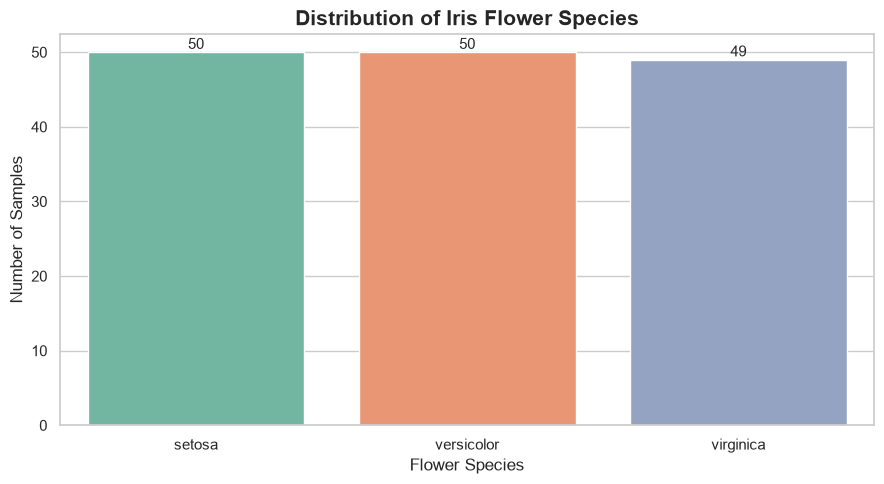


Species Distribution Analysis Completed!


In [6]:
# ==================================================
# Step 6: Exploratory Data Analysis (EDA)
# Species Distribution
# ==================================================

# Count flower species
species_counts = df["species"].value_counts()

print("=" * 50)
print("IRIS FLOWER SPECIES DISTRIBUTION")
print("=" * 50)

print("\nSpecies Counts:")
print(species_counts)

# Create professional visualization
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="species",
    hue="species",
    palette="Set2",
    legend=False
)

# Add count labels
for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.title("Distribution of Iris Flower Species", fontsize=15, fontweight="bold")
plt.xlabel("Flower Species", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)

plt.tight_layout()
plt.show()

print("\nSpecies Distribution Analysis Completed!")

IRIS FLOWER - FEATURE DISTRIBUTION ANALYSIS


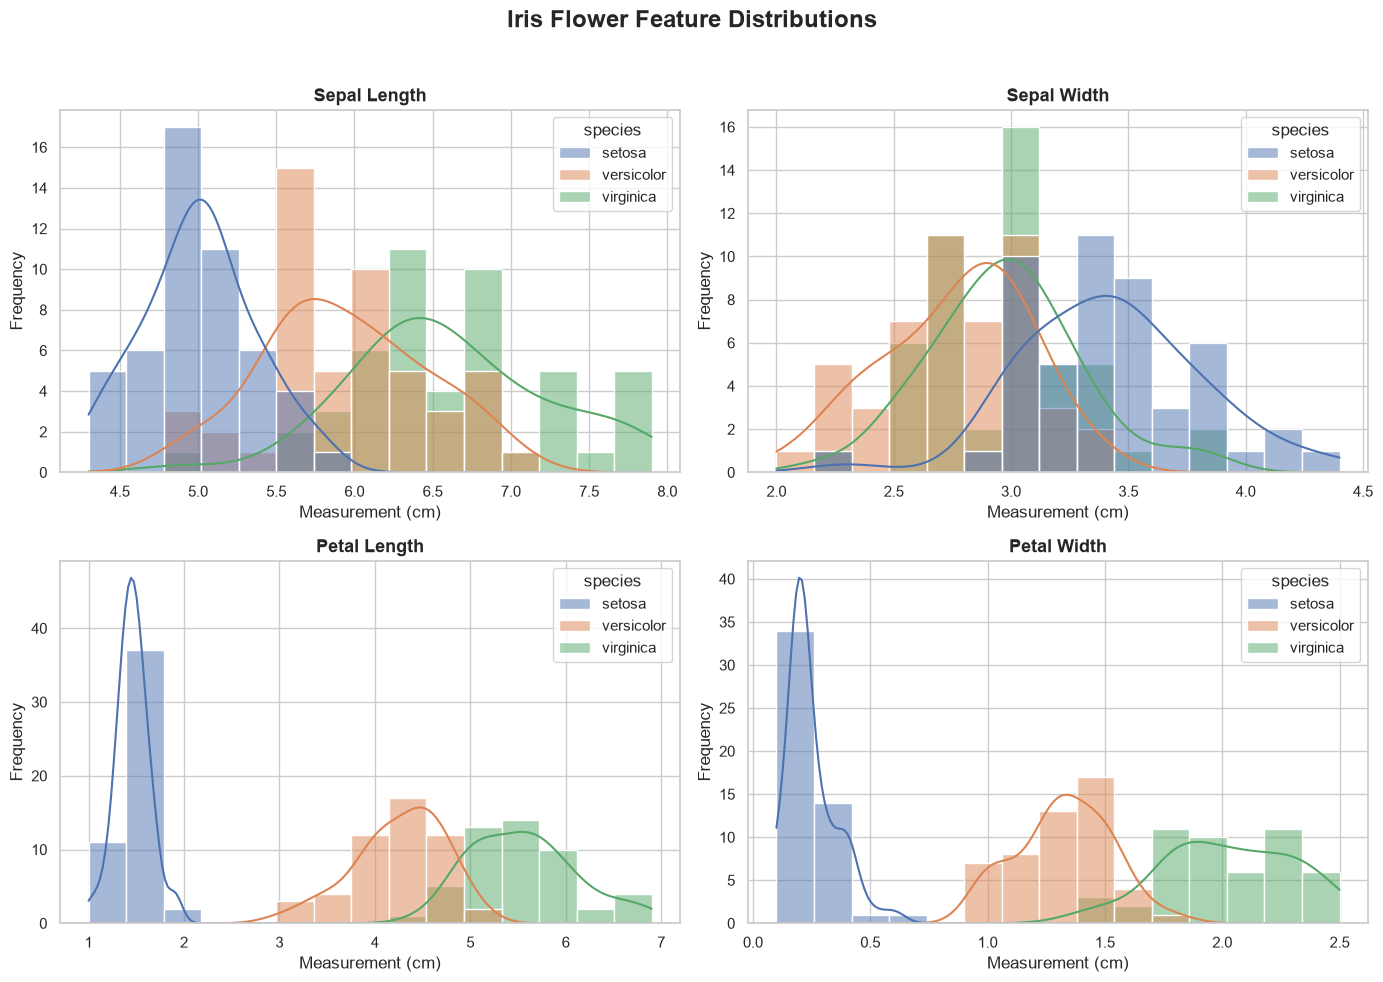


Feature Distribution Analysis Completed Successfully!


In [7]:
# ==================================================
# Step 7: Feature Distribution Analysis
# ==================================================

print("=" * 50)
print("IRIS FLOWER - FEATURE DISTRIBUTION ANALYSIS")
print("=" * 50)

# Define numerical features
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Create four distribution plots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue="species",
        kde=True,
        bins=15,
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Measurement (cm)")
    ax.set_ylabel("Frequency")

# Main title
fig.suptitle(
    "Iris Flower Feature Distributions",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

print("\nFeature Distribution Analysis Completed Successfully!")

IRIS FLOWER - CORRELATION ANALYSIS

Correlation Matrix:


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.00,-0.12,0.87,0.82
sepal_width,-0.12,1.00,-0.43,-0.36
petal_length,0.87,-0.43,1.00,0.96
petal_width,0.82,-0.36,0.96,1.00


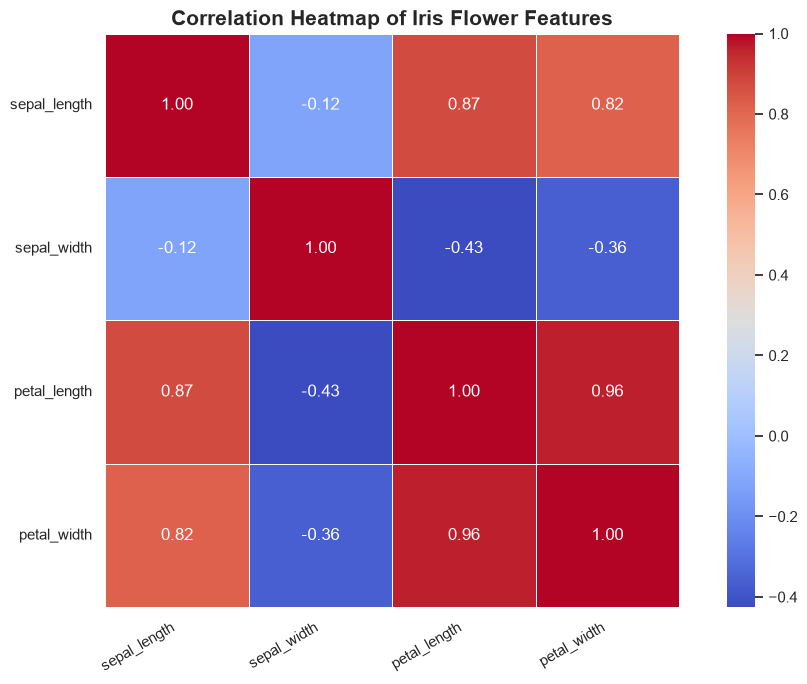


Correlation Analysis Completed Successfully!


In [8]:
# ==================================================
# Step 8: Correlation Heatmap Analysis
# ==================================================

print("=" * 50)
print("IRIS FLOWER - CORRELATION ANALYSIS")
print("=" * 50)

# Select numerical features
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Calculate correlation matrix
correlation_matrix = df[features].corr()

# Display correlation values
print("\nCorrelation Matrix:")
display(correlation_matrix.round(2))

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar=True
)

plt.title(
    "Correlation Heatmap of Iris Flower Features",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

print("\nCorrelation Analysis Completed Successfully!")

In [9]:
# ==================================================
# Step 9: Train-Test Split
# ==================================================

print("=" * 50)
print("IRIS FLOWER - TRAIN TEST SPLIT")
print("=" * 50)

# Select input features
X = df[
    [
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
]

# Select target variable
y = df["target"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split information
print("\nTotal Dataset Samples:", len(X))
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Features:", X_train.shape[1])

print("\nTraining Class Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Class Distribution:")
print(y_test.value_counts().sort_index())

print("\nTrain-Test Split Completed Successfully!")

IRIS FLOWER - TRAIN TEST SPLIT

Total Dataset Samples: 149
Training Samples: 119
Testing Samples: 30
Number of Features: 4

Training Class Distribution:
target
0    40
1    40
2    39
Name: count, dtype: int64

Testing Class Distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64

Train-Test Split Completed Successfully!


In [10]:
# ==================================================
# Step 10: Train Machine Learning Models
# ==================================================

print("=" * 50)
print("IRIS FLOWER - MODEL TRAINING")
print("=" * 50)

# Initialize Machine Learning Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train all models using training data
for model_name, model in models.items():

    model.fit(X_train, y_train)

    print(f"\n{model_name} trained successfully!")

print("\n" + "=" * 50)
print("ALL MACHINE LEARNING MODELS TRAINED SUCCESSFULLY!")
print("=" * 50)

IRIS FLOWER - MODEL TRAINING

Logistic Regression trained successfully!

Decision Tree trained successfully!

Random Forest trained successfully!

ALL MACHINE LEARNING MODELS TRAINED SUCCESSFULLY!


IRIS FLOWER - MODEL ACCURACY COMPARISON

Model Performance Results:


,Model,Accuracy (%)
0,Logistic Regression,96.67
1,Decision Tree,93.33
2,Random Forest,93.33



Best Performing Model: Logistic Regression
Best Model Accuracy: 96.67%


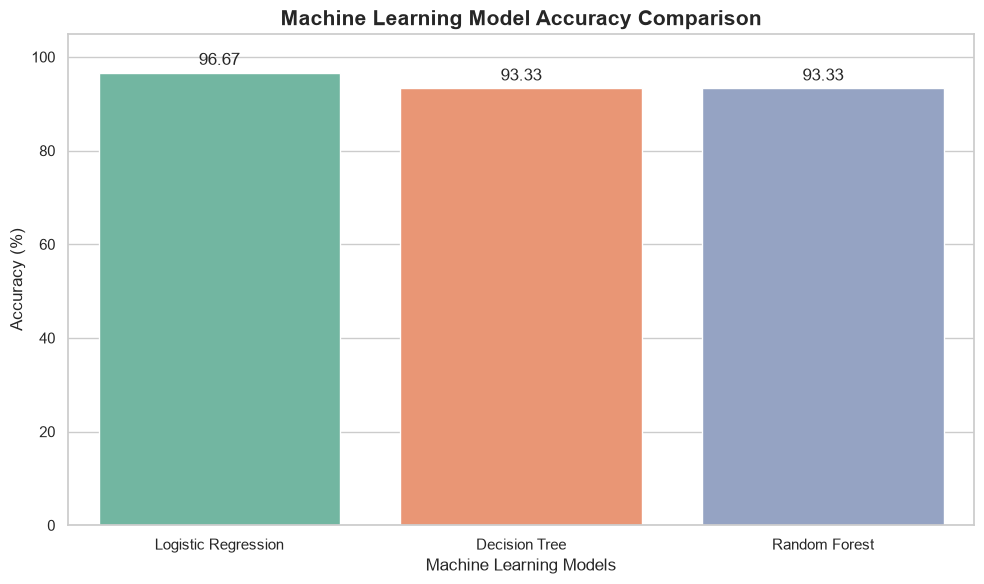


Model Comparison Completed Successfully!


In [11]:
# ==================================================
# Step 11: Model Evaluation & Accuracy Comparison
# ==================================================

print("=" * 50)
print("IRIS FLOWER - MODEL ACCURACY COMPARISON")
print("=" * 50)

# Store model evaluation results
results = []

# Evaluate each trained model
for model_name, model in models.items():

    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": model_name,
        "Accuracy (%)": round(accuracy * 100, 2)
    })

# Create results DataFrame
results_df = pd.DataFrame(results)

# Sort models by accuracy
results_df = results_df.sort_values(
    by="Accuracy (%)",
    ascending=False
).reset_index(drop=True)

# Display comparison table
print("\nModel Performance Results:")
display(results_df)

# Select best model
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]
best_accuracy = results_df.loc[0, "Accuracy (%)"]

print("\nBest Performing Model:", best_model_name)
print(f"Best Model Accuracy: {best_accuracy:.2f}%")

# Visualize model comparison
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)",
    hue="Model",
    palette="Set2",
    legend=False
)

# Add accuracy labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title(
    "Machine Learning Model Accuracy Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

plt.tight_layout()
plt.show()

print("\nModel Comparison Completed Successfully!")

IRIS FLOWER - BEST MODEL EVALUATION

Best Model: Logistic Regression
Accuracy: 96.67%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



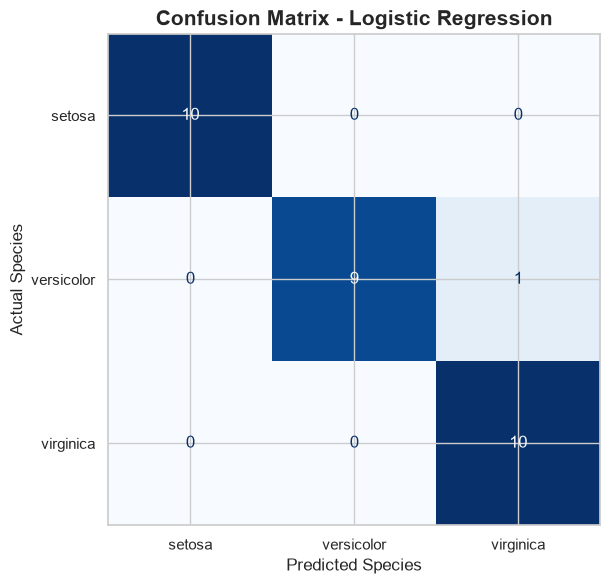


Best Model Evaluation Completed Successfully!


In [12]:
# ==================================================
# Step 12: Best Model Evaluation
# Classification Report and Confusion Matrix
# ==================================================

print("=" * 50)
print("IRIS FLOWER - BEST MODEL EVALUATION")
print("=" * 50)

# Make predictions using the best model
y_pred_best = best_model.predict(X_test)

# Display best model information
print("\nBest Model:", best_model_name)
print(f"Accuracy: {best_accuracy:.2f}%")

# Generate classification report
print("\nCLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=iris.target_names
    )
)

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")

plt.tight_layout()
plt.show()

print("\nBest Model Evaluation Completed Successfully!")

In [13]:
# ==================================================
# Step 13: Save Best Trained Machine Learning Model
# ==================================================

print("=" * 50)
print("IRIS FLOWER - MODEL SAVING")
print("=" * 50)

# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Define model file path
model_path = "../models/iris_logistic_regression.pkl"

# Save the best trained model
joblib.dump(best_model, model_path)

# Verify saved model
if os.path.exists(model_path):
    print("\nModel saved successfully!")
    print("Model Name:", best_model_name)
    print(f"Model Accuracy: {best_accuracy:.2f}%")
    print("Saved File:", model_path)
    print("File Size:", os.path.getsize(model_path), "bytes")
else:
    print("\nError: Model could not be saved!")

print("\nModel Saving Process Completed!")

IRIS FLOWER - MODEL SAVING

Model saved successfully!
Model Name: Logistic Regression
Model Accuracy: 96.67%
Saved File: ../models/iris_logistic_regression.pkl
File Size: 1295 bytes

Model Saving Process Completed!


In [14]:
# ==================================================
# Step 14: Load Saved Model and Predict New Flower
# ==================================================

print("=" * 50)
print("IRIS FLOWER - NEW FLOWER PREDICTION")
print("=" * 50)

# Load the saved machine learning model
loaded_model = joblib.load(model_path)

print("\nSaved model loaded successfully!")

# New flower measurements (in centimeters)
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ]
)

# Display input measurements
print("\nNew Flower Measurements:")
display(new_flower)

# Predict flower species
prediction = loaded_model.predict(new_flower)

# Convert predicted class into species name
predicted_species = iris.target_names[prediction[0]]

# Calculate prediction probabilities
probabilities = loaded_model.predict_proba(new_flower)

confidence = probabilities.max() * 100

# Display prediction
print("\n" + "=" * 50)
print("PREDICTION RESULTS")
print("=" * 50)

print("Predicted Flower Species:", predicted_species)
print(f"Model Confidence: {confidence:.2f}%")

print("\nPrediction completed successfully!")

IRIS FLOWER - NEW FLOWER PREDICTION

Saved model loaded successfully!

New Flower Measurements:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2



PREDICTION RESULTS
Predicted Flower Species: setosa
Model Confidence: 97.84%

Prediction completed successfully!


SAVING MODEL EVALUATION RESULTS

Model comparison CSV saved successfully!


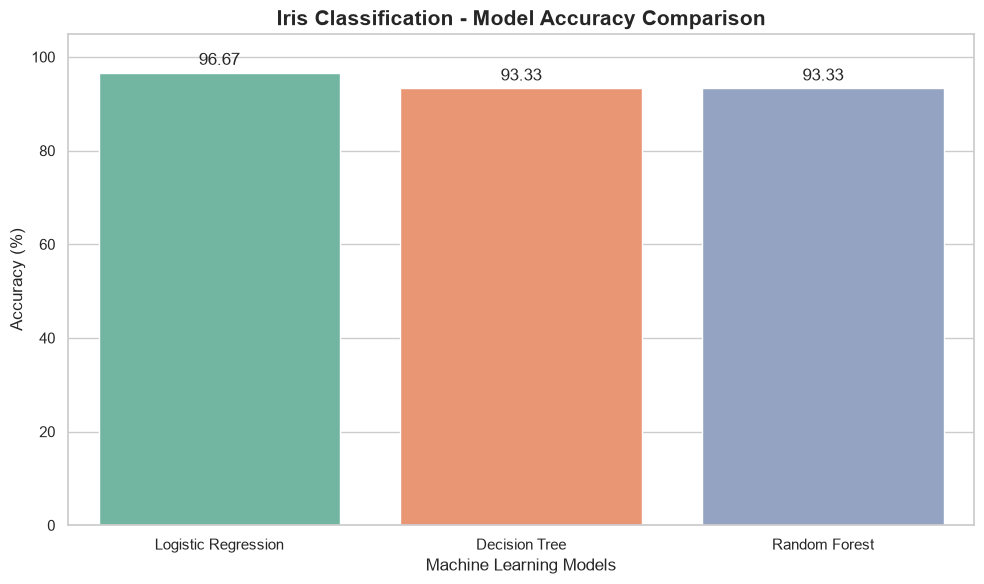


Saved Files:
1. ../results/model_comparison.csv - True
2. ../results/model_accuracy_comparison.png - True

Results saved successfully!


In [15]:
# ==================================================
# Step 15: Save Model Evaluation Results
# ==================================================

print("=" * 50)
print("SAVING MODEL EVALUATION RESULTS")
print("=" * 50)

# Create results folder
os.makedirs("../results", exist_ok=True)

# Save accuracy comparison as CSV
csv_path = "../results/model_comparison.csv"

results_df.to_csv(csv_path, index=False)

print("\nModel comparison CSV saved successfully!")

# Create accuracy comparison chart
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy (%)",
    hue="Model",
    palette="Set2",
    legend=False,
    ax=ax
)

# Add accuracy labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

ax.set_title(
    "Iris Classification - Model Accuracy Comparison",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Machine Learning Models")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 105)

plt.tight_layout()

# Save chart as high-quality image
chart_path = "../results/model_accuracy_comparison.png"

fig.savefig(chart_path, dpi=300, bbox_inches="tight")

plt.show()

# Verify saved files
print("\nSaved Files:")
print("1.", csv_path, "-", os.path.exists(csv_path))
print("2.", chart_path, "-", os.path.exists(chart_path))

print("\nResults saved successfully!")

SAVING CONFUSION MATRIX


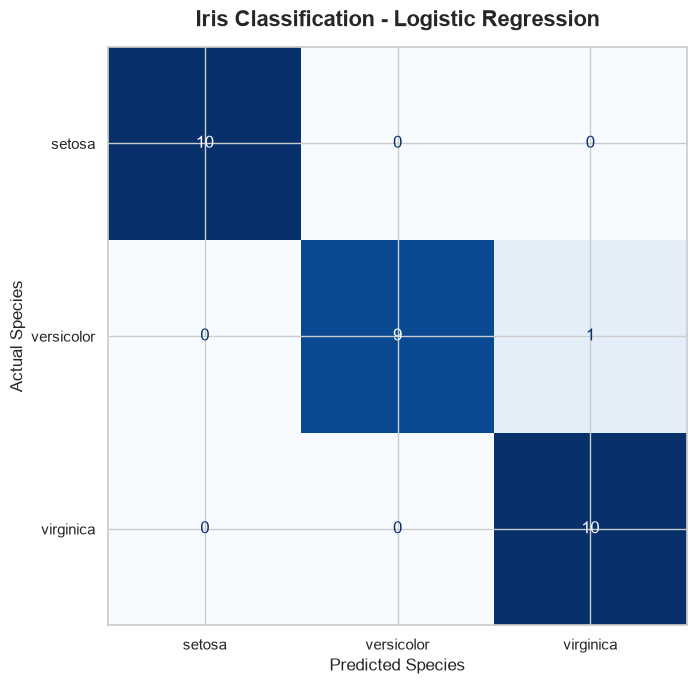


Confusion Matrix Saved Successfully!
File: ../results/confusion_matrix.png
File Exists: True


In [16]:
# ==================================================
# Step 16: Save Confusion Matrix Visualization
# ==================================================

print("=" * 50)
print("SAVING CONFUSION MATRIX")
print("=" * 50)

# Generate predictions using the best model
y_pred_best = best_model.predict(X_test)

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Create professional visualization
fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(
    f"Iris Classification - {best_model_name}",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Predicted Species", fontsize=12)
ax.set_ylabel("Actual Species", fontsize=12)

plt.tight_layout()

# Save confusion matrix
confusion_matrix_path = "../results/confusion_matrix.png"

fig.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Verify saved file
print("\nConfusion Matrix Saved Successfully!")
print("File:", confusion_matrix_path)
print("File Exists:", os.path.exists(confusion_matrix_path))

SAVING EXPLORATORY DATA ANALYSIS GRAPHS


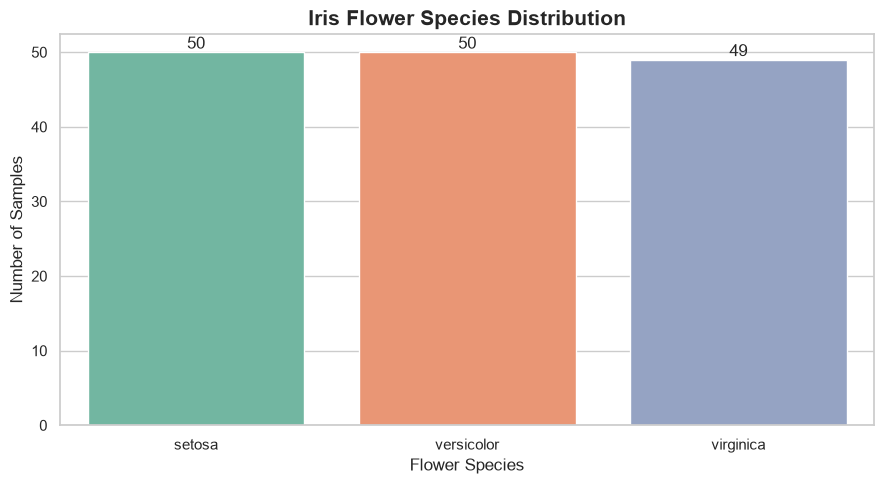

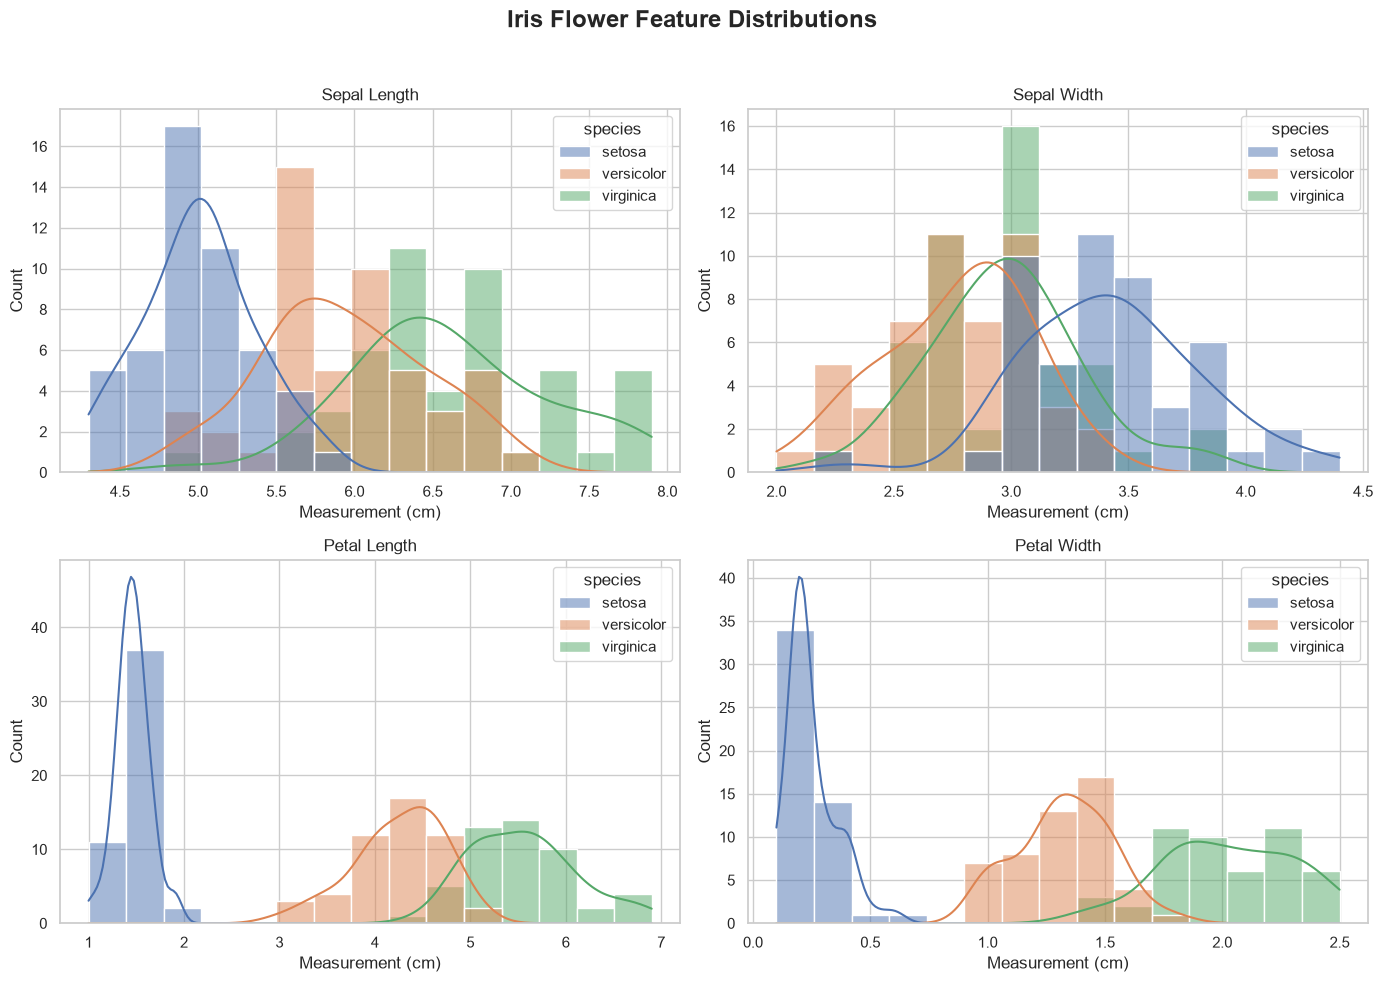

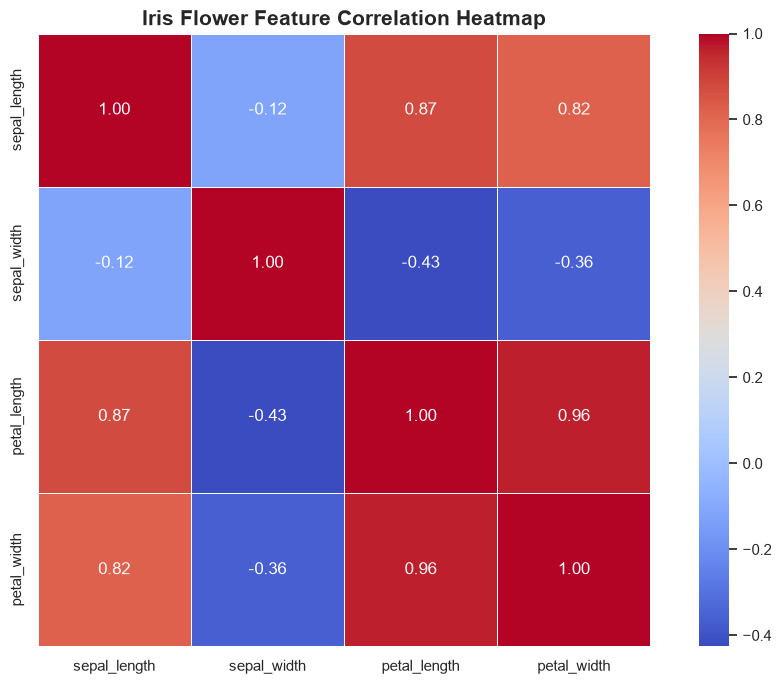


SAVED EDA FILES:
species_distribution.png: True
feature_distributions.png: True
correlation_heatmap.png: True

EDA Visualizations Saved Successfully!


In [17]:
# ==================================================
# Step 17: Save EDA Visualizations
# ==================================================

print("=" * 50)
print("SAVING EXPLORATORY DATA ANALYSIS GRAPHS")
print("=" * 50)

# Create results folder
os.makedirs("../results", exist_ok=True)

# --------------------------------------------------
# 1. Species Distribution
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

sns.countplot(
    data=df,
    x="species",
    hue="species",
    palette="Set2",
    legend=False,
    ax=ax
)

for container in ax.containers:
    ax.bar_label(container)

ax.set_title("Iris Flower Species Distribution",
             fontsize=15, fontweight="bold")
ax.set_xlabel("Flower Species")
ax.set_ylabel("Number of Samples")

plt.tight_layout()

fig.savefig(
    "../results/species_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 2. Feature Distribution
# --------------------------------------------------

features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        hue="species",
        kde=True,
        bins=15,
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Measurement (cm)")

fig.suptitle(
    "Iris Flower Feature Distributions",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

fig.savefig(
    "../results/feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 3. Correlation Heatmap
# --------------------------------------------------

correlation_matrix = df[features].corr()

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    square=True,
    ax=ax
)

ax.set_title(
    "Iris Flower Feature Correlation Heatmap",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    "../results/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# Verify Saved Files
# --------------------------------------------------

print("\nSAVED EDA FILES:")

files = [
    "species_distribution.png",
    "feature_distributions.png",
    "correlation_heatmap.png"
]

for file in files:
    path = os.path.join("../results", file)
    print(f"{file}: {os.path.exists(path)}")

print("\nEDA Visualizations Saved Successfully!")